# Tahap 1: Persiapan Data & Ekspor Foto

In [ ]:
# # === SEL 1: MOUNT DRIVE, LOAD 127 FOTO ASLI, & FUNGSI PIPELINE PCD V2 ===
# import os
# import re
# import cv2
# import glob
# import zipfile
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from google.colab import drive, files

# drive.mount('/content/drive')

# DATASET_DIR = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset'
# MANUAL_MASK_DIR = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Manual_Masks'
# OUT_P3_DIR = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Progress_3_Outputs'
# os.makedirs(MANUAL_MASK_DIR, exist_ok=True)
# os.makedirs(OUT_P3_DIR, exist_ok=True)

# # 1. Baca 127 foto mentah dengan urutan identik Notebook 02 agar id_daun (LEAF_001..127) 100% sama
# folder_map = {'P1_Sehat': 'Sehat', 'P1_Menguning': 'Menguning', 'P1_Kering': 'Kering'}
# records = []
# for folder_name, label_final in folder_map.items():
#     folder_path = os.path.join(DATASET_DIR, folder_name)
#     for fname in sorted(os.listdir(folder_path)):
#         if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
#             continue
#         fpath = os.path.join(folder_path, fname)
#         if cv2.imread(fpath) is None:
#             continue
#         m = re.search(r'(\d{8})_(\d{6})', fname)
#         date_str = m.group(1) if m else 'Unknown'
#         sesi = 1 if date_str == '20261022' else (2 if date_str == '20261028' else 0)
#         records.append({'filename': fname, 'filepath': fpath, 'label_final': label_final, 'sesi': sesi})

# df_clean = pd.DataFrame(records).reset_index(drop=True)
# df_clean['id_daun'] = [f"LEAF_{i+1:03d}" for i in range(len(df_clean))]

# # 2. Helper & Fungsi Pipeline PCD v2 (identik 100% dengan Notebook 02)
# WORK_LONG = 800

# def resize_long(img, long_side=WORK_LONG):
#     h, w = img.shape[:2]
#     s = long_side / max(h, w)
#     return cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)

# def mean_L(img_bgr):
#     return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)[:, :, 0].mean() / 255.0

# def adaptive_gamma_lab(img_bgr, target, lo=0.8, hi=1.25):
#     lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
#     m = float(np.clip(lab[:, :, 0].mean() / 255.0, 0.05, 0.95))
#     g = float(np.clip(np.log(target) / np.log(m), lo, hi))
#     lut = (((np.arange(256) / 255.0) ** g) * 255).astype(np.uint8)
#     lab[:, :, 0] = cv2.LUT(lab[:, :, 0], lut)
#     return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), g

# def apply_bilateral(img_bgr, d=9, sigma_color=75, sigma_space=75):
#     return cv2.bilateralFilter(img_bgr, d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)

# def apply_clahe_lab(img_bgr, clip_limit=2.0, tile_size=(8, 8)):
#     lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
#     l, a, b = cv2.split(lab)
#     clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
#     l_clahe = clahe.apply(l)
#     return cv2.cvtColor(cv2.merge([l_clahe, a, b]), cv2.COLOR_LAB2BGR)

# def segment_leaf_otsu_morph(img_bgr):
#     lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
#     hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
#     _, _, b = cv2.split(lab)
#     _, s, _ = cv2.split(hsv)
#     _, mask_b = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
#     _, mask_s = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
#     mask_raw = cv2.bitwise_or(mask_b, mask_s)
#     kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
#     mask_clean = cv2.morphologyEx(mask_raw, cv2.MORPH_OPEN, kernel, iterations=1)
#     mask_clean = cv2.morphologyEx(mask_clean, cv2.MORPH_CLOSE, kernel, iterations=2)
#     num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask_clean, connectivity=8)
#     if num_labels > 1:
#         largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
#         mask_clean = np.where(labels == largest_label, 255, 0).astype(np.uint8)
#     return mask_raw, mask_clean

# WORK_IMGS = {i: resize_long(cv2.imread(r['filepath'])) for i, r in df_clean.iterrows()}
# TARGET_L = float(np.median([mean_L(im) for im in WORK_IMGS.values()]))

# print(f"Berhasil memuat {len(df_clean)} foto asli | Target L* = {TARGET_L:.3f}")
# print(pd.crosstab(df_clean['sesi'], df_clean['label_final'], margins=True))

Mounted at /content/drive


In [1]:
# === SEL 1 (VERSI CEPAT ±3 DETIK): MOUNT DRIVE, METADATA, & LAZY LOADER ===
import os
import re
import cv2
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive, files

drive.mount('/content/drive')

DATASET_DIR = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset'
MANUAL_MASK_DIR = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Manual_Masks'
OUT_P3_DIR = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Progress_3_Outputs'
os.makedirs(MANUAL_MASK_DIR, exist_ok=True)
os.makedirs(OUT_P3_DIR, exist_ok=True)

# 1. Baca metadata 127 foto mentah dari nama file saja (tanpa cv2.imread agar instan)
folder_map = {'P1_Sehat': 'Sehat', 'P1_Menguning': 'Menguning', 'P1_Kering': 'Kering'}
records = []
for folder_name, label_final in folder_map.items():
    folder_path = os.path.join(DATASET_DIR, folder_name)
    for fname in sorted(os.listdir(folder_path)):
        if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            continue
        fpath = os.path.join(folder_path, fname)
        m = re.search(r'(\d{8})_(\d{6})', fname)
        date_str = m.group(1) if m else 'Unknown'
        sesi = 1 if date_str == '20261022' else (2 if date_str == '20261028' else 0)
        records.append({'filename': fname, 'filepath': fpath, 'label_final': label_final, 'sesi': sesi})

df_clean = pd.DataFrame(records).reset_index(drop=True)
df_clean['id_daun'] = [f"LEAF_{i+1:03d}" for i in range(len(df_clean))]

# 2. Helper & Fungsi Pipeline PCD v2 (identik 100% dengan Notebook 02)
WORK_LONG = 800
TARGET_L = 0.716  # Nilai median dataset 127 foto hasil perhitungan Notebook 02

def resize_long(img, long_side=WORK_LONG):
    h, w = img.shape[:2]
    s = long_side / max(h, w)
    return cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)

def adaptive_gamma_lab(img_bgr, target, lo=0.8, hi=1.25):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    m = float(np.clip(lab[:, :, 0].mean() / 255.0, 0.05, 0.95))
    g = float(np.clip(np.log(target) / np.log(m), lo, hi))
    lut = (((np.arange(256) / 255.0) ** g) * 255).astype(np.uint8)
    lab[:, :, 0] = cv2.LUT(lab[:, :, 0], lut)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), g

def apply_bilateral(img_bgr, d=9, sigma_color=75, sigma_space=75):
    return cv2.bilateralFilter(img_bgr, d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)

def apply_clahe_lab(img_bgr, clip_limit=2.0, tile_size=(8, 8)):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
    l_clahe = clahe.apply(l)
    return cv2.cvtColor(cv2.merge([l_clahe, a, b]), cv2.COLOR_LAB2BGR)

def segment_leaf_otsu_morph(img_bgr):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    _, _, b = cv2.split(lab)
    _, s, _ = cv2.split(hsv)
    _, mask_b = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, mask_s = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask_raw = cv2.bitwise_or(mask_b, mask_s)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask_clean = cv2.morphologyEx(mask_raw, cv2.MORPH_OPEN, kernel, iterations=1)
    mask_clean = cv2.morphologyEx(mask_clean, cv2.MORPH_CLOSE, kernel, iterations=2)
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask_clean, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mask_clean = np.where(labels == largest_label, 255, 0).astype(np.uint8)
    return mask_raw, mask_clean

# Lazy loader: hanya membaca foto dari Drive ketika dipanggil oleh Sel 3 (21 foto saja)
class LazyWorkImgs:
    def __init__(self, df):
        self.df = df
        self.cache = {}
    def __getitem__(self, idx):
        if idx not in self.cache:
            img = cv2.imread(self.df.loc[idx, 'filepath'])
            self.cache[idx] = resize_long(img)
        return self.cache[idx]

WORK_IMGS = LazyWorkImgs(df_clean)

print(f"Siap! {len(df_clean)} metadata foto dimuat instan | Target L* = {TARGET_L:.3f}")
print(pd.crosstab(df_clean['sesi'], df_clean['label_final'], margins=True))

Mounted at /content/drive
Siap! 137 metadata foto dimuat instan | Target L* = 0.716
label_final  Kering  Menguning  Sehat  All
sesi                                      
1                23         40     22   85
2                22         11     19   52
All              45         51     41  137


In [ ]:
# === SEL 2: EKSPOR 21 FOTO UNTUK ROBOFLOW & 30 FOTO BLIND LABELING ===
# A. Sampling 21 foto mask manual (7 Sehat, 7 Menguning, 7 Kering; tiap kelas 4 Sesi 1 + 3 Sesi 2)
samples_mask = []
for kelas in ['Sehat', 'Menguning', 'Kering']:
    s1 = df_clean[(df_clean['label_final'] == kelas) & (df_clean['sesi'] == 1)].sample(n=4, random_state=42)
    s2 = df_clean[(df_clean['label_final'] == kelas) & (df_clean['sesi'] == 2)].sample(n=3, random_state=42)
    samples_mask.extend([s1, s2])
df_21 = pd.concat(samples_mask).sort_values('id_daun')

os.makedirs('/content/export_21_mask', exist_ok=True)
zip_mask_path = os.path.join(OUT_P3_DIR, '21_Foto_Mask_Manual.zip')
with zipfile.ZipFile(zip_mask_path, 'w') as zf:
    for idx, row in df_21.iterrows():
        fname = f"{row['id_daun']}.jpg"
        p_tmp = os.path.join('/content/export_21_mask', fname)
        cv2.imwrite(p_tmp, WORK_IMGS[idx])
        zf.write(p_tmp, arcname=fname)

print("1. 21 Foto Mask Manual siap (tersimpan juga di Drive Progress_3_Outputs):")
print(pd.crosstab(df_21['sesi'], df_21['label_final'], margins=True))

# B. Paket Blind Labeling 30 foto (fokus zona transisi Menguning vs Kering)
b_sehat = df_clean[df_clean['label_final'] == 'Sehat'].sample(n=6, random_state=42)
b_kun   = df_clean[df_clean['label_final'] == 'Menguning'].sample(n=12, random_state=42)
b_ker   = df_clean[df_clean['label_final'] == 'Kering'].sample(n=12, random_state=42)
df_blind = pd.concat([b_sehat, b_kun, b_ker]).sample(frac=1, random_state=42).reset_index()

os.makedirs('/content/export_blind', exist_ok=True)
zip_blind_path = os.path.join(OUT_P3_DIR, 'Paket_Blind_Labeling_Tim.zip')
kunci_rows, lembar_rows = [], []
with zipfile.ZipFile(zip_blind_path, 'w') as zf:
    for i, row in df_blind.iterrows():
        bid = f"BLIND_{i+1:02d}"
        p_tmp = os.path.join('/content/export_blind', f"{bid}.jpg")
        cv2.imwrite(p_tmp, WORK_IMGS[row['index']])
        zf.write(p_tmp, arcname=f"{bid}.jpg")
        kunci_rows.append({'blind_id': bid, 'id_daun': row['id_daun'], 'sesi': row['sesi'], 'label_nadhif_rifat': row['label_final']})
        lembar_rows.append({'blind_id': bid, 'label_adita': '', 'label_ammar': ''})

kunci_csv = os.path.join(OUT_P3_DIR, 'KUNCI_RAHASIA_Blind_Labeling.csv')
lembar_csv = os.path.join(OUT_P3_DIR, 'Lembar_Isian_Tim.csv')
pd.DataFrame(kunci_rows).to_csv(kunci_csv, index=False)
pd.DataFrame(lembar_rows).to_csv(lembar_csv, index=False)

# Download otomatis ke laptop
files.download(zip_mask_path)
files.download(zip_blind_path)
files.download(lembar_csv)

1. 21 Foto Mask Manual siap (tersimpan juga di Drive Progress_3_Outputs):
label_final  Kering  Menguning  Sehat  All
sesi                                      
1                 4          4      4   12
2                 3          3      3    9
All               7          7      7   21


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Konversi Mask & Hitung IoU/Dice

loading Roboflow workspace...
Export started (id=3CZpAQmBAa). Polling for completion...
If this takes too long, you can check the export status at: https://api.roboflow.com/nadhifs-workspace/search/export/3CZpAQmBAa?api_key=YOUR_API_KEY


Extracting search export to /content/rf_api_dataset: 100%|██████████| 24/24 [00:00<00:00, 2987.57it/s]


Search export extracted to /content/rf_api_dataset
Dataset berhasil diunduh ke: /content/rf_api_dataset
Berhasil mengonversi & menyimpan 21 mask manual biner ke: /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Manual_Masks

=== TABEL 1: RINGKASAN IoU & DICE (N = 21 MASK MANUAL) ===
                         IoU                            Dice                  \
                        mean     std     min     max    mean     std     min   
metode                                                                         
GrabCut               0.3753  0.2661  0.0783  0.9589  0.4990  0.2567  0.1453   
K-Means (a*,b*)       0.8280  0.2977  0.1296  0.9800  0.8668  0.2533  0.2294   
Otsu a*               0.3178  0.4436  0.0006  0.9717  0.3366  0.4549  0.0011   
Otsu b*+S (Pipeline)  0.9628  0.0382  0.8016  0.9835  0.9806  0.0214  0.8899   

                              
                         max  
metode                        
GrabCut               0.9790  
K-Means (a*,b*

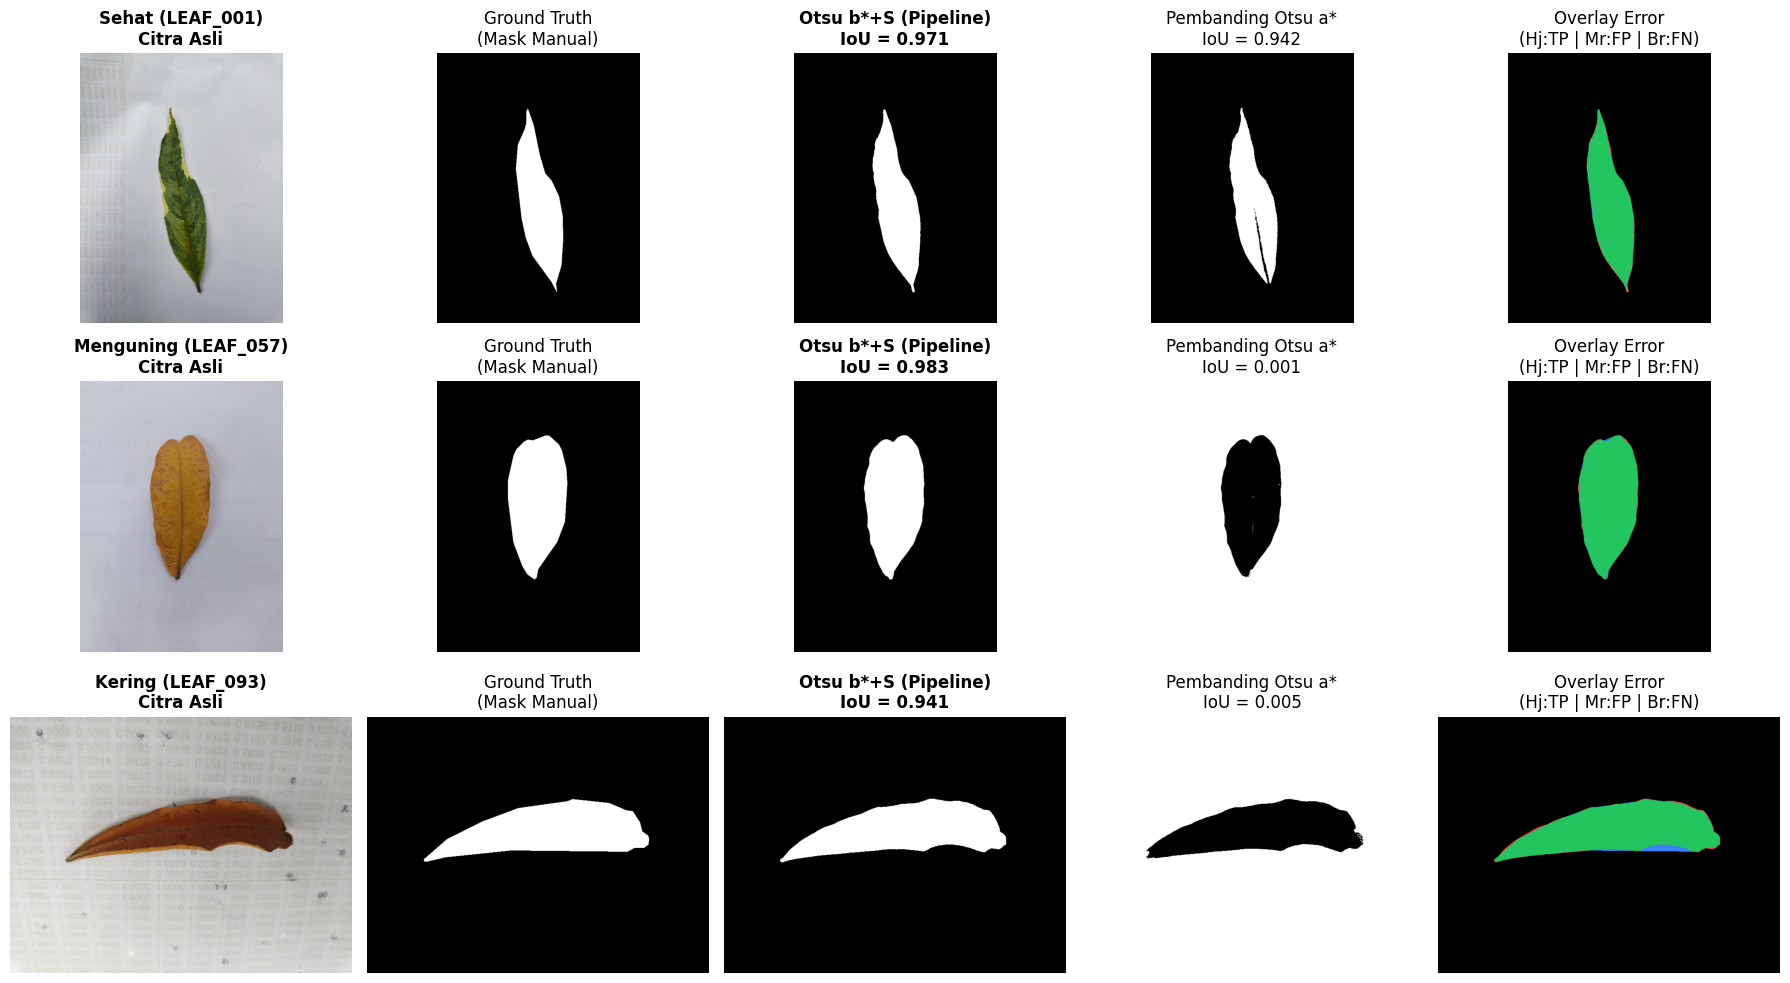

Grafik presentasi tersimpan di: /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Progress_3_Outputs/P3_Evaluasi_Segmentasi_E7_Overlay.png


In [3]:
# === SEL 3: TARIK DATASET VIA ROBOFLOW API, KONVERSI MASK PNG, & EVALUASI E7 ===
!pip install -q -U roboflow

import json
import shutil
from roboflow import Roboflow

# 1. Unduh dataset langsung ke folder sementara Colab lewat API Roboflow
EXTRACT_DIR = '/content/rf_api_dataset'
if os.path.exists(EXTRACT_DIR):
    shutil.rmtree(EXTRACT_DIR)

rf = Roboflow(api_key="mqzu0AtL172Rw5BZNWr3")
workspace = rf.workspace("nadhifs-workspace")
dataset_path = workspace.search_export(
    query='filename:"LEAF_*"',
    format="coco-segmentation",
    dataset="project-akhir-comvis",
    location=EXTRACT_DIR,
)
print("Dataset berhasil diunduh ke:", dataset_path)

# 2. Konversi koordinat poligon COCO JSON menjadi 21 file mask biner (LEAF_xxx.png)
coco_jsons = glob.glob(os.path.join(EXTRACT_DIR, '**', '*coco*.json'), recursive=True)
saved = 0
for jp in coco_jsons:
    with open(jp, 'r', encoding='utf-8') as f:
        coco = json.load(f)

    images_map = {img['id']: img for img in coco.get('images', [])}
    anns_by_img = {}
    for ann in coco.get('annotations', []):
        anns_by_img.setdefault(ann['image_id'], []).append(ann)

    for img_id, img_info in images_map.items():
        m = re.search(r'(LEAF_\d{3})', img_info.get('file_name', ''))
        anns = anns_by_img.get(img_id, [])
        if not m or not anns:
            continue

        lid = m.group(1)
        h, w = int(img_info['height']), int(img_info['width'])
        mask_bin = np.zeros((h, w), dtype=np.uint8)
        for ann in anns:
            segs = ann.get('segmentation', [])
            if isinstance(segs, list):
                for poly in segs:
                    if isinstance(poly, list) and len(poly) >= 6:
                        pts = np.array(poly, dtype=np.float32).reshape(-1, 2)
                        cv2.fillPoly(mask_bin, [np.round(pts).astype(np.int32)], 255)

        if mask_bin.sum() > 0:
            cv2.imwrite(os.path.join(MANUAL_MASK_DIR, f"{lid}.png"), mask_bin)
            saved += 1

print(f"Berhasil mengonversi & menyimpan {saved} mask manual biner ke: {MANUAL_MASK_DIR}")
assert saved > 0, "0 mask tersimpan! Periksa kembali hasil export JSON dari Roboflow."

# 3. Evaluasi Kuantitatif E7: Otsu b*+S (Pipeline) vs Otsu a* vs K-Means vs GrabCut
def iou_dice(pred, gt):
    p, g = pred > 0, gt > 0
    inter = np.logical_and(p, g).sum()
    union = np.logical_or(p, g).sum()
    return inter / max(union, 1), 2 * inter / max(p.sum() + g.sum(), 1)

def seg_a_star(img):
    a = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[:, :, 1]
    _, m = cv2.threshold(a, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return m

def seg_kmeans(img, k=3):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[:, :, 1:].reshape(-1, 2).astype(np.float32)
    _, lbl, _ = cv2.kmeans(lab, k, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0), 3, cv2.KMEANS_PP_CENTERS)
    grid = lbl.reshape(img.shape[:2])
    border = np.concatenate([grid[0], grid[-1]])
    bg = np.bincount(border.astype(int), minlength=k).argmax()
    return np.where(grid != bg, 255, 0).astype(np.uint8)

def seg_grabcut(img):
    h, w = img.shape[:2]
    m = np.zeros((h, w), np.uint8)
    bgd, fgd = np.zeros((1, 65)), np.zeros((1, 65))
    cv2.grabCut(img, m, (int(.05*w), int(.05*h), int(.9*w), int(.9*h)), bgd, fgd, 3, cv2.GC_INIT_WITH_RECT)
    return np.where((m == 1) | (m == 3), 255, 0).astype(np.uint8)

rows = []
vis_samples = {}
for p in sorted(glob.glob(os.path.join(MANUAL_MASK_DIR, '*.png'))):
    lid = os.path.splitext(os.path.basename(p))[0]
    idx_list = df_clean.index[df_clean['id_daun'] == lid]
    if len(idx_list) == 0:
        continue
    idx = idx_list[0]
    kelas = df_clean.loc[idx, 'label_final']
    sesi = df_clean.loc[idx, 'sesi']
    im = WORK_IMGS[idx]
    g, _ = adaptive_gamma_lab(im, TARGET_L)
    c1 = apply_clahe_lab(apply_bilateral(g), 2.0)
    gt = cv2.resize(cv2.imread(p, 0), (im.shape[1], im.shape[0]), interpolation=cv2.INTER_NEAREST)

    preds = {
        'Otsu b*+S (Pipeline)': segment_leaf_otsu_morph(c1)[1],
        'Otsu a*': seg_a_star(c1),
        'K-Means (a*,b*)': seg_kmeans(c1),
        'GrabCut': seg_grabcut(im)
    }
    for nm, m_pred in preds.items():
        i_, d_ = iou_dice(m_pred, gt)
        rows.append({'id_daun': lid, 'kelas': kelas, 'sesi': sesi, 'metode': nm, 'IoU': i_, 'Dice': d_})

    if kelas not in vis_samples:
        vis_samples[kelas] = (lid, im, gt, preds['Otsu b*+S (Pipeline)'], preds['Otsu a*'])

df_seg = pd.DataFrame(rows)
df_seg.to_csv(os.path.join(OUT_P3_DIR, 'Hasil_Evaluasi_Segmentasi_E7.csv'), index=False)

print(f"\n=== TABEL 1: RINGKASAN IoU & DICE (N = {df_seg['id_daun'].nunique()} MASK MANUAL) ===")
print(df_seg.groupby('metode')[['IoU', 'Dice']].agg(['mean', 'std', 'min', 'max']).round(4))

print("\n=== TABEL 2: RATA-RATA IoU PER KELAS ===")
print(df_seg.pivot_table(index='metode', columns='kelas', values='IoU', aggfunc='mean').round(4))

print("\n=== TABEL 3: RATA-RATA IoU PER SESI ===")
print(df_seg.pivot_table(index='metode', columns='sesi', values='IoU', aggfunc='mean').round(4))

# 4. Grafik Visualisasi Perbandingan 3 Kelas (300 dpi) untuk Slide Presentasi
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for r_idx, kls in enumerate(['Sehat', 'Menguning', 'Kering']):
    if kls not in vis_samples:
        continue
    lid, im, gt, pred_bs, pred_a = vis_samples[kls]
    iou_bs, _ = iou_dice(pred_bs, gt)
    iou_a, _ = iou_dice(pred_a, gt)

    overlay = np.zeros((*gt.shape, 3), dtype=np.uint8)
    p_b, g_b = pred_bs > 0, gt > 0
    overlay[p_b & g_b] = [34, 197, 94]
    overlay[p_b & ~g_b] = [239, 68, 68]
    overlay[~p_b & g_b] = [59, 130, 246]

    axes[r_idx, 0].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    axes[r_idx, 0].set_title(f"{kls} ({lid})\nCitra Asli", fontweight='bold')
    axes[r_idx, 1].imshow(gt, cmap='gray')
    axes[r_idx, 1].set_title("Ground Truth\n(Mask Manual)")
    axes[r_idx, 2].imshow(pred_bs, cmap='gray')
    axes[r_idx, 2].set_title(f"Otsu b*+S (Pipeline)\nIoU = {iou_bs:.3f}", fontweight='bold')
    axes[r_idx, 3].imshow(pred_a, cmap='gray')
    axes[r_idx, 3].set_title(f"Pembanding Otsu a*\nIoU = {iou_a:.3f}")
    axes[r_idx, 4].imshow(overlay)
    axes[r_idx, 4].set_title("Overlay Error\n(Hj:TP | Mr:FP | Br:FN)")
    for c_idx in range(5):
        axes[r_idx, c_idx].axis('off')

plt.tight_layout()
fig_path = os.path.join(OUT_P3_DIR, 'P3_Evaluasi_Segmentasi_E7_Overlay.png')
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Grafik presentasi tersimpan di: {fig_path}")

In [ ]:
# # === SEL 4: HITUNG INTER-ANNOTATOR AGREEMENT (COHEN'S KAPPA) ===
# from sklearn.metrics import cohen_kappa_score, confusion_matrix

# df_kunci = pd.read_csv(os.path.join(OUT_P3_DIR, 'KUNCI_RAHASIA_Blind_Labeling.csv'))
# df_isian = pd.read_csv(os.path.join(OUT_P3_DIR, 'Lembar_Isian_Tim.csv'))
# df_eval = df_kunci.merge(df_isian, on='blind_id')

# # Bersihkan spasi dan kapitalisasi agar tidak error karena salah ketik ringan
# for col in ['label_nadhif_rifat', 'label_adita', 'label_ammar']:
#     df_eval[col] = df_eval[col].astype(str).str.strip().str.capitalize()

# k_rifat_adita = cohen_kappa_score(df_eval['label_nadhif_rifat'], df_eval['label_adita'])
# k_rifat_ammar = cohen_kappa_score(df_eval['label_nadhif_rifat'], df_eval['label_ammar'])
# k_adita_ammar = cohen_kappa_score(df_eval['label_adita'], df_eval['label_ammar'])

# print(f"Kappa (Nadhif Rif'at vs Nadhif Adita) : {k_rifat_adita:.4f}")
# print(f"Kappa (Nadhif Rif'at vs Ammar)        : {k_rifat_ammar:.4f}")
# print(f"Kappa (Nadhif Adita vs Ammar)         : {k_adita_ammar:.4f}")
# print(f"Rata-rata Inter-Annotator Kappa       : {np.mean([k_rifat_adita, k_rifat_ammar, k_adita_ammar]):.4f}")

# # Cek foto mana saja yang tidak disepakati ketiga anggota (kasus borderline sejati)
# disagree = df_eval[
#     (df_eval['label_nadhif_rifat'] != df_eval['label_adita']) |
#     (df_eval['label_nadhif_rifat'] != df_eval['label_ammar'])
# ]
# print(f"\nJumlah foto dengan perbedaan pendapat: {len(disagree)} / {len(df_eval)}")
# print(disagree[['blind_id', 'id_daun', 'sesi', 'label_nadhif_rifat', 'label_adita', 'label_ammar']])